# ETF Effects: Primary vs. Secondary Market Activities — a replication lab

**Paper:** Comerton-Forde, C. & Marta, T. (2025). *ETF effects: The role of primary versus secondary market activities.*
Journal of Financial Markets, 75, 100983. [doi:10.1016/j.finmar.2025.100983](https://doi.org/10.1016/j.finmar.2025.100983)

The authors' data (Euronext trade-level HFT flags, 5-minute LSEG quotes) are proprietary and not shared, so this notebook rebuilds the paper's **mechanisms and estimators** on simulated data. It then provides **real-data modules** that run on open sources (Yahoo Finance, Bank of Japan statistics) and need an internet connection.

| § | Content | Paper counterpart | Data | Internet needed |
|---|---|---|---|---|
| 0 | Setup & econometric toolkit | — | — | no |
| 1 | The paper in brief | §1 | — | no |
| 2 | Simulation lab I: AP arbitrage vs. HFT trading | §2, Tables 2–4, Fig. 1 | simulated | no |
| 3 | Simulation lab II: constituent-stock market quality | §3, Table 5 | simulated | no |
| 4 | The Bank of Japan experiment: design & Monte Carlo | §4, Tables 7–8 | simulated | no |
| 5 | Real data I: BoJ experiment on Japanese stocks | §4, Table 8 + our extension | BoJ CSV + Yahoo | yes |
| 6 | Real data II: ETF vs. basket liquidity; trend check | Table 6, Table 9 | Yahoo | yes |
| 7 | Takeaways & limitations | §6 | — | no |

**How to run:** open the notebook in Jupyter (`jupyter lab`) or VS Code and run all cells; the first code cell installs any missing packages. Sections 0–4 need no internet. Sections 5–6 download market data and skip themselves gracefully if a source is unreachable.

## 0. Setup

In [1]:
import importlib, subprocess, sys

def ensure(pkg, pip_name=None):
    try:
        return importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg])
        return importlib.import_module(pkg)

for pkg, pip_name in [("linearmodels", None), ("bidask", None), ("yfinance", None), ("statsmodels", None)]:
    ensure(pkg, pip_name)
print("packages ready")

packages ready


In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 20)

SEED = 2025
DATA_DIR = Path("data")      # put the optional CSVs for §5 here
FIG_DIR = Path("figures")    # figures are saved here (used in the slides)
FIG_DIR.mkdir(exist_ok=True)

# Chart style: one validated categorical order, recessive grid, thin marks
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a",
         ink="#0b0b0b", ink2="#52514e", muted="#898781", grid="#e1e0d9", axis="#c3c2b7", surface="#fcfcfb")
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["axis"], "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.6,
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110, "savefig.dpi": 200,
    "savefig.bbox": "tight", "font.family": "sans-serif",
})

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

### Econometric toolkit

Every regression in the paper has the same backbone: **OLS with entity and day fixed effects and standard errors double-clustered by entity and day** (Cameron, Gelbach & Miller, 2011). `fe_ols` below implements it directly:

1. **Within transformation.** Alternating projections remove entity and/or day means; for a balanced panel one pass is exact.
2. **Two-way clustered covariance:** $\hat V = \hat V_{entity} + \hat V_{day} - \hat V_{White}$.

It is ~1,000× faster than `linearmodels.PanelOLS` on the 600k-row Japanese panel, and the next cell checks that both give identical coefficients and near-identical standard errors.

In [3]:
def winsorize(s, p=0.01):
    lo, hi = s.quantile([p, 1 - p])
    return s.clip(lo, hi)


def _demean(X, groups, tol=1e-10, max_iter=500):
    X = X.copy()
    counts = [np.bincount(g)[:, None] for g in groups]
    for _ in range(max_iter):
        worst = 0.0
        for g, cnt in zip(groups, counts):
            sums = np.zeros((cnt.shape[0], X.shape[1]))
            np.add.at(sums, g, X)
            means = (sums / cnt)[g]
            X -= means
            worst = max(worst, np.abs(means).max())
        if worst < tol or len(groups) == 1:
            break
    return X


def _cluster_meat(Xu, g):
    S = np.zeros((g.max() + 1, Xu.shape[1]))
    np.add.at(S, g, Xu)
    return S.T @ S


def fe_ols(df, y, xs, entity, time, effects=("entity", "time"), cluster=("entity", "time")):
    # OLS with fixed effects and one- or two-way clustered SEs; returns (coef table, info dict)
    d = df[[y, *xs, entity, time]].replace([np.inf, -np.inf], np.nan).dropna()
    g = {"entity": pd.factorize(d[entity])[0], "time": pd.factorize(d[time])[0]}
    Z = _demean(d[[y, *xs]].to_numpy(float), [g[e] for e in effects])
    yy, X = Z[:, 0], Z[:, 1:]
    XtX_inv = np.linalg.inv(X.T @ X)
    b = XtX_inv @ X.T @ yy
    u = yy - X @ b
    Xu = X * u[:, None]
    n, k = X.shape
    adj = lambda G: G / (G - 1) * (n - 1) / (n - k)
    parts = {c: adj(g[c].max() + 1) * _cluster_meat(Xu, g[c]) for c in cluster}
    if len(cluster) == 2:
        meat = parts["entity"] + parts["time"] - (n - 1) / (n - k) * (Xu.T @ Xu)
    else:
        meat = parts[cluster[0]]
    V = XtX_inv @ meat @ XtX_inv
    if np.any(np.diag(V) <= 0):   # two-way formula can fail to be PSD in tiny samples
        V = XtX_inv @ np.maximum(parts["entity"], parts["time"]) @ XtX_inv
    se = np.sqrt(np.diag(V))
    r2 = 1 - (u @ u) / ((yy - yy.mean()) ** 2).sum()
    table = pd.DataFrame({"coef": b, "se": se, "t": b / se}, index=xs)
    return table, {"N": n, "R2 (within)": r2, "effects": "+".join(effects) or "none"}


def stars(t):
    a = abs(t)
    return "***" if a > 2.576 else "**" if a > 1.96 else "*" if a > 1.645 else ""


def reg_table(models, rows, labels=None, extra=None):
    # Paper-style table: coef + stars, (se) below; one column per model
    labels = labels or {}
    out = {}
    for name, (tab, info) in models.items():
        col = {}
        for r in rows:
            if r in tab.index:
                c, s, t = tab.loc[r, ["coef", "se", "t"]]
                col[labels.get(r, r)] = f"{c:.3f}{stars(t)}"
                col[labels.get(r, r) + " "] = f"({s:.3f})"
            else:
                col[labels.get(r, r)] = ""
                col[labels.get(r, r) + " "] = ""
        col["Fixed effects"] = info["effects"]
        for k, v in (extra or {}).get(name, {}).items():
            col[k] = v
        col["Observations"] = f"{info['N']:,}"
        col["R² (within)"] = f"{info['R2 (within)']:.3f}"
        out[name] = col
    return pd.DataFrame(out)


def z_test(b_a, se_a, b_b, se_b):
    # Eq. (13): difference between two independent slope estimates
    return (b_a - b_b) / np.sqrt(se_a ** 2 + se_b ** 2)

## 1. The paper in brief

**Two markets, two types of traders.**

- **Primary market:** *Authorized Participants* (APs) create ETF units by delivering the basket of stocks, or redeem units for the basket. They do it when the ETF trades away from its NAV (a premium or discount), and in doing so they enforce the law of one price.
- **Secondary market:** ETF units trade on the exchange. On Euronext Paris, **HFTs** account for ≈74% of ETF volume but do **not** take part in creation or redemption.

```
 investors ──trade units──► exchange (HFT ≈ 74% of volume) ◄──► ETF price
                                                                   │ mispricing = (Price − NAV)/NAV
 APs ──creation / redemption──► ETF issuer ◄──basket of stocks──► constituent stocks
```

**Two channels to the constituent stocks**

| Channel | Who | Mechanism | Predicted effect on stocks |
|---|---|---|---|
| Arbitrage | APs (primary market) | basket trades transmit non-fundamental demand shocks | volatility ↑, spreads ↑, efficiency ↓ |
| Information linkage | HFTs (secondary market) | quotes in the ETF diffuse information to the basket | spreads ↓, efficiency ↑ |

**Key equations**

$$PMActivity_{e,t} = \frac{N_{e,t}-N_{e,t-1}}{N_{e,t-1}}\qquad HFTActivity_{e,t}=\log(1+V^{HFT}_{e,t})\qquad ETFMispricing_{e,t}=\frac{P_{e,t}-NAV_{e,t}}{NAV_{e,t}}$$

$$(5)\;\; PrimaryActivity_{e,t} = \alpha_e + \beta_1 ETFMispricing_{e,t} + \beta_2 HFTActivity_{e,t} + \eta_t + \varepsilon_{e,t}$$

$$(10)\;\; Y_{i,t} = \alpha_i + \beta_1 (ETFOwn_{i,t}\times|PMActivity_t|) + \beta_2 (ETFOwn_{i,t}\times HFTActivity_t) + \eta_t + \varphi'X_{i,t} + \varepsilon_{i,t}$$

$$(11)\;\; PMStockActivity_{i,t} = \frac{\sum_{ETF} BoJPurchases_{ETF,t}\times w_{ETF,i,t}}{MarketValue_{i,t-22}}\qquad (12)\;\; Y_{i,t} = \alpha_i + \lambda_t + \beta_1 PMStockActivity_{i,t} + \varepsilon_{i,t}$$

**Headline findings**

1. Primary-market activity occurs on only **32%** of ETF-days, and its volume is ≈ **13%** of secondary-market volume.
2. Creations and redemptions follow **mispricing**, especially large mispricing (limits to arbitrage). HFT activity is unrelated to both.
3. Primary-market activity goes with higher volatility, wider spreads and lower efficiency in stocks the ETF holds heavily. HFT activity goes with **narrower** spreads.
4. In Japan, BoJ-driven creations **cause** higher returns, volatility and illiquidity in overweighted stocks.
5. ETF ownership in Japan rose sharply in 2010–2016 while market quality improved, so the secondary-market benefits appear to dominate.

**Paper, Table 8 Panel A (BoJ purchase days) and implied economic size**

,coef,se,sample mean,Z (A vs B),effect of avg. purchase (0.33) as % of mean
Return,0.239,0.054,-1.010,2.210,7.809
Volatility,1.901,0.505,40.590,1.700,1.546
QuotedSpread,0.011,0.005,0.200,3.970,1.815
Depth,-0.943,0.214,5.290,-3.160,-5.883


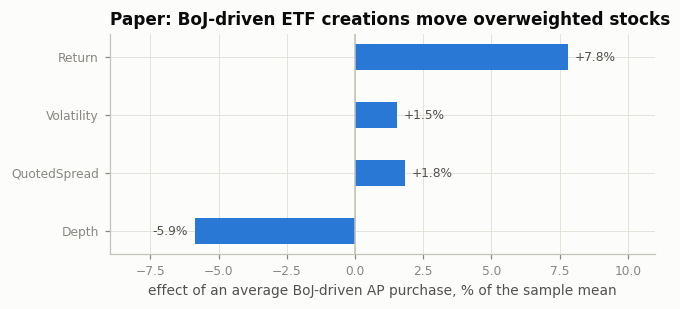

In [4]:
# The paper's headline estimates (Tables 3, 5, 8), typed in for comparison with our results later
PAPER = {
    "table2": pd.Series({"PM days (share)": 0.32, "s.d. PMActivity (%)": 2.23, "s.d. mispricing (%)": 0.37,
                         "mean |mispricing| (%)": 0.21, "HFT share of volume (%)": 73.81,
                         "PM volume / secondary volume": 0.13}),
    "table3": {"|PMActivity| on |ETFMispricing|": (0.079, 0.036), "1_PM on |ETFMispricing|": (0.025, 0.010),
               "PMActivity on ETFMispricing": (0.245, 0.091), "|PMActivity| on HFTActivity": (0.003, 0.009)},
    "table5": pd.DataFrame({"ETFOwn × |PMActivity|": [0.029, 0.004, 0.017, 0.038],
                            "ETFOwn × HFTActivity": [0.013, -0.006, 0.004, -0.027]},
                           index=["Volatility", "QuotedSpread", "Depth", "Inefficiency"]),
    "table8": pd.DataFrame({"coef": [0.239, 1.901, 0.011, -0.943], "se": [0.054, 0.505, 0.005, 0.214],
                            "sample mean": [-1.01, 40.59, 0.20, 5.29], "Z (A vs B)": [2.21, 1.70, 3.97, -3.16]},
                           index=["Return", "Volatility", "QuotedSpread", "Depth"]),
}
t8 = PAPER["table8"].copy()
t8["effect of avg. purchase (0.33) as % of mean"] = 100 * t8["coef"] * 0.33 / t8["sample mean"].abs()
display(Markdown("**Paper, Table 8 Panel A (BoJ purchase days) and implied economic size**"))
display(t8.round(3))

fig, ax = plt.subplots(figsize=(6.4, 2.6))
vals = t8["effect of avg. purchase (0.33) as % of mean"].values
names = t8.index.tolist()
ypos = np.arange(len(names))[::-1]
ax.barh(ypos, vals, height=0.45, color=C["blue"])
for yv, v in zip(ypos, vals):
    ax.text(v + (0.25 if v > 0 else -0.25), yv, f"{v:+.1f}%", va="center",
            ha="left" if v > 0 else "right", fontsize=8, color=C["ink2"])
ax.set_yticks(ypos, names)
ax.axvline(0, color=C["axis"], lw=1)
ax.set_xlim(-9, 11)
ax.set_xlabel("effect of an average BoJ-driven AP purchase, % of the sample mean")
ax.set_title("Paper: BoJ-driven ETF creations move overweighted stocks")
savefig(fig, "paper_table8_effects")
plt.show()

## 2. Simulation lab I — AP arbitrage vs. HFT trading (paper §2)

We cannot see Euronext's HFT flags, but we can write down the economics the paper describes, simulate a market with **known truth**, and check what the paper's regressions recover.

**Model (one ETF $e$, day $t$)**

- **Mispricing.** Pre-arbitrage mispricing follows $\pi^*_{e,t} = \rho\,\pi_{e,t-1} + \sigma_e\,\tfrac{VIX_t}{24}\,z_{e,t}$, i.e. demand shocks scaled by a volatility index. Observed mispricing adds NAV-measurement noise (stale NAVs, closing-time mismatch) and a fund-specific NAV-convention offset. Following the paper, we demean it by ETF.
- **AP arbitrage with limits to arbitrage.** If $|\pi^*_{e,t}| > c_e$ (the arbitrage cost), an AP creates (premium) or redeems (discount) a whole number of **creation units** with probability $p$; capacity and inventory limits make it miss some opportunities. Arbitrage removes a share $\phi$ of the excess mispricing.
- **Investor flows.** On a share $q$ of days, in-kind creations or redemptions happen for reasons unrelated to mispricing.
- **HFTs.** Secondary-market volume depends on fund size and market volatility, and HFTs take an ETF-specific share of it. By default HFT volume is **independent of mispricing and of the primary market**; the switch `hft_arbitrage` lets HFTs trade the basis.

Larger ETFs face lower costs and smaller shocks. The calibration targets the paper's Table 2: PM activity on ≈32% of days, mispricing s.d. ≈0.37%, HFT share ≈74%, and PM volume ≈13% of secondary volume.

In [5]:
def simulate_market(n_days=252, seed=SEED):
    # A VSTOXX-like volatility index (log-AR(1) with a late-summer spike) and a market return
    rng = np.random.default_rng(seed)
    lv = np.empty(n_days)
    lv[0] = np.log(24)
    for t in range(1, n_days):
        lv[t] = np.log(24) + 0.95 * (lv[t - 1] - np.log(24)) + 0.06 * rng.standard_normal()
    spike = 0.45 * np.exp(-0.5 * ((np.arange(n_days) - 160) / 6) ** 2)
    vix = np.exp(lv + spike)
    mkt_ret = 100 * vix / 100 / np.sqrt(252) * rng.standard_normal(n_days)
    return pd.DataFrame({"vix": vix, "mkt_ret": mkt_ret}, index=pd.bdate_range("2015-01-02", periods=n_days))


def simulate_etf_panel(market, n_etf=34, cost_scale=1.0, hft_arbitrage=0.0, seed=SEED + 1,
                       rho=0.5, phi=0.8, p_act=0.7, p_flow=0.12, cu_units=50_000, meas_sd=0.28):
    rng = np.random.default_rng(seed)
    T, vix = len(market), market["vix"].to_numpy()
    mv = np.exp(rng.normal(np.log(260), 1.5, n_etf))       # market value, EUR m (Table 2: median 260)
    mv[0] = 3800.0                                         # ETF00 = the "Lyxor CAC 40" of our market
    size = np.log(mv / 260)
    price = rng.uniform(20, 150, n_etf)
    units = mv * 1e6 / price
    sig_u = 0.22 * np.exp(-0.15 * size)                    # mispricing-shock s.d., %
    cost = cost_scale * 0.24 * np.exp(-0.15 * size)        # arbitrage cost threshold, %
    cu_pct = np.clip(cu_units / units * 100, 0.2, 8.0)     # one creation unit, % of units outstanding
    nav_bias = rng.normal(0, 0.05, n_etf)
    turnover = np.exp(rng.normal(np.log(0.02), 0.6, n_etf))
    hft_base = rng.beta(6, 2, n_etf)
    pi_post, rows = np.zeros(n_etf), []
    for t in range(T):
        vol_scale = vix[t] / 24
        pi_star = rho * pi_post + sig_u * vol_scale * rng.standard_normal(n_etf)
        excess = np.abs(pi_star) - cost
        arb = (excess > 0) & (rng.random(n_etf) < p_act)
        n_cu = np.where(arb, 1 + rng.poisson(np.clip(excess, 0, None) / cost * 1.5), 0)
        pm = np.sign(pi_star) * n_cu * cu_pct
        flow = rng.random(n_etf) < p_flow
        pm = pm + np.where(flow, rng.choice([-1, 1], n_etf) * (1 + rng.poisson(0.5, n_etf)) * cu_pct, 0)
        pi_post = np.where(arb, pi_star - np.sign(pi_star) * excess * phi, pi_star)
        volume = units * turnover * np.exp(0.6 * np.log(vol_scale) + 0.5 * rng.standard_normal(n_etf))
        volume *= 1 + hft_arbitrage * np.abs(pi_star) / 0.2
        hft_share = np.clip(hft_base + 0.08 * rng.standard_normal(n_etf), 0, 1)
        hft_units = volume * hft_share * (rng.random(n_etf) > 0.03)
        hft_net = hft_units * 0.1 * rng.standard_normal(n_etf)          # HFT net buying (signed)
        if hft_arbitrage:
            hft_net += hft_units * 0.1 * np.sign(pi_star) * hft_arbitrage
        rows.append(pd.DataFrame({
            "etf": [f"ETF{e:02d}" for e in range(n_etf)], "date": market.index[t],
            "PMActivity": pm, "mis_true": pi_star, "mis_raw": pi_star + nav_bias + meas_sd * rng.standard_normal(n_etf),
            "volume_units": volume, "hft_units": hft_units, "hft_net": hft_net,
            "pm_units": np.abs(pm) / 100 * units, "MarketValue": np.log(mv),
            "vix": vix[t], "mkt_ret": market["mkt_ret"].iloc[t]}))
        units = units * (1 + pm / 100)
    d = pd.concat(rows, ignore_index=True)
    d["ETFMispricing"] = d["mis_raw"] - d.groupby("etf")["mis_raw"].transform("mean")
    d["HFT_pct"] = 100 * d["hft_units"] / d["volume_units"]
    d["HFTActivity"] = np.log1p(d["hft_units"])
    d["SignedHFTActivity"] = np.sign(d["hft_net"]) * np.log1p(d["hft_net"].abs())
    for col in ["PMActivity", "ETFMispricing", "HFTActivity", "SignedHFTActivity"]:
        d[col] = winsorize(d[col])                               # paper: 1% / 99% winsorisation
    d["absPMActivity"] = d["PMActivity"].abs()
    d["PM_indicator"] = (d["absPMActivity"] > 0).astype(float)
    d["absMispricing"] = d["ETFMispricing"].abs()
    d["HighMis_median"] = (d["absMispricing"] > d.groupby("etf")["absMispricing"].transform("median")).astype(float)
    d["HighMis_tercile"] = (d["absMispricing"] > d.groupby("etf")["absMispricing"].transform(lambda s: s.quantile(2 / 3))).astype(float)
    d = d.sort_values(["etf", "date"])
    for col in ["absPMActivity", "PM_indicator", "PMActivity"]:
        d[f"{col}_lag"] = d.groupby("etf")[col].shift(1)
        d[f"{col}_lead"] = d.groupby("etf")[col].shift(-1)
    return d.reset_index(drop=True)


market = simulate_market()
etf = simulate_etf_panel(market)
print(f"simulated panel: {etf['etf'].nunique()} ETFs x {etf['date'].nunique()} days = {len(etf):,} ETF-days")

simulated panel: 34 ETFs x 252 days = 8,568 ETF-days


### 2.1 Descriptive statistics (paper Table 2) and Figure 1

,Paper (Euronext 2015),Simulation
PM days (share),0.320,0.306
s.d. PMActivity (%),2.230,2.432
s.d. mispricing (%),0.370,0.358
mean |mispricing| (%),0.210,0.288
HFT share of volume (%),73.810,69.737
PM volume / secondary volume,0.130,0.104


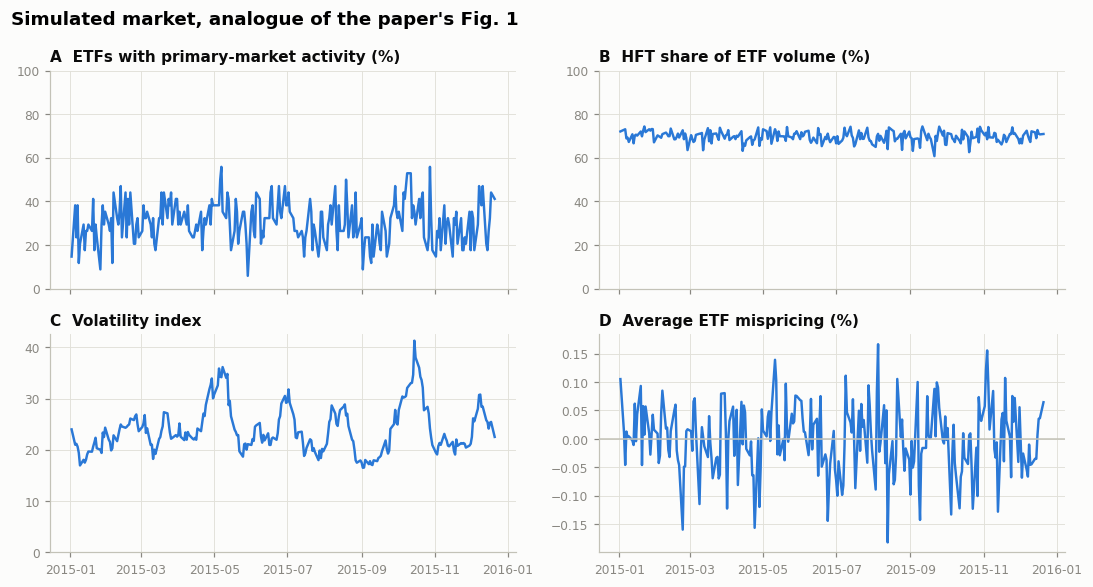

In [6]:
sim_t2 = pd.Series({
    "PM days (share)": etf["PM_indicator"].mean(),
    "s.d. PMActivity (%)": etf["PMActivity"].std(),
    "s.d. mispricing (%)": etf["ETFMispricing"].std(),
    "mean |mispricing| (%)": etf["absMispricing"].mean(),
    "HFT share of volume (%)": etf["HFT_pct"].mean(),
    "PM volume / secondary volume": etf["pm_units"].sum() / etf["volume_units"].sum(),
})
display(pd.DataFrame({"Paper (Euronext 2015)": PAPER["table2"], "Simulation": sim_t2}).round(3))

daily = etf.groupby("date").agg(pm_share=("PM_indicator", "mean"), hft=("HFT_pct", "mean"),
                                vix=("vix", "first"), mis=("ETFMispricing", "mean"))
fig, axes = plt.subplots(2, 2, figsize=(10, 5.4), sharex=True)
panels = [("pm_share", "A  ETFs with primary-market activity (%)", 100, (0, 100)),
          ("hft", "B  HFT share of ETF volume (%)", 1, (0, 100)),
          ("vix", "C  Volatility index", 1, (0, None)),
          ("mis", "D  Average ETF mispricing (%)", 1, (None, None))]
for ax, (col, title, scale, ylim) in zip(axes.ravel(), panels):
    ax.plot(daily.index, daily[col] * scale, color=C["blue"])
    ax.set_title(title, fontsize=10)
    ax.set_ylim(*ylim)
axes[1, 1].axhline(0, color=C["axis"], lw=1)
fig.suptitle("Simulated market, analogue of the paper's Fig. 1", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "sim_fig1_market")
plt.show()

### 2.2 What drives primary-market activity? (paper Table 3)

Columns follow the paper:

1. ETF and day fixed effects.
2. ETF fixed effects plus macro controls (the volatility index and the market return) instead of day fixed effects.
3. Column 1 plus one lead and one lag of the dependent variable.
4. An indicator for above-median $|mispricing|$.
5. An indicator for top-tercile $|mispricing|$.

In [7]:
def table3_panel(d, dep, mis="absMispricing", hft="HFTActivity"):
    m = {}
    m["(1)"] = fe_ols(d, dep, [mis, hft, "MarketValue"], "etf", "date")
    m["(2)"] = fe_ols(d, dep, [mis, hft, "vix", "mkt_ret"], "etf", "date", effects=("entity",))
    m["(3)"] = fe_ols(d, dep, [mis, hft, f"{dep}_lag", f"{dep}_lead"], "etf", "date")
    if dep != "PMActivity":
        m["(4)"] = fe_ols(d, dep, ["HighMis_median", hft], "etf", "date")
        m["(5)"] = fe_ols(d, dep, ["HighMis_tercile", hft], "etf", "date")
    return m

labels = {"absMispricing": "|ETFMispricing|", "ETFMispricing": "ETFMispricing", "HighMis_median": "1[|mis| > median]",
          "HighMis_tercile": "1[|mis| top tercile]", "HFTActivity": "HFTActivity", "SignedHFTActivity": "SignedHFTActivity"}

panelA = table3_panel(etf, "absPMActivity")
panelB = table3_panel(etf, "PM_indicator")
panelC = table3_panel(etf, "PMActivity", mis="ETFMispricing", hft="SignedHFTActivity")
rowsAB = ["absMispricing", "HighMis_median", "HighMis_tercile", "HFTActivity"]
for title, panel, rows in [("Panel A: |PMActivity| (magnitude)", panelA, rowsAB),
                           ("Panel B: 1_PM (frequency)", panelB, rowsAB),
                           ("Panel C: PMActivity (signed)", panelC, ["ETFMispricing", "SignedHFTActivity"])]:
    display(Markdown(f"**{title}**"))
    display(reg_table(panel, rows, labels))

**Panel A: |PMActivity| (magnitude)**

,(1),(2),(3),(4),(5)
|ETFMispricing|,1.864***,1.874***,1.878***,,
|ETFMispricing|,(0.272),(0.302),(0.279),,
1[|mis| > median],,,,0.523***,
1[|mis| > median],,,,(0.088),
1[|mis| top tercile],,,,,0.665***
1[|mis| top tercile],,,,,(0.114)
HFTActivity,-0.009,-0.009,-0.010,-0.012,-0.009
HFTActivity,(0.012),(0.012),(0.012),(0.012),(0.013)
Fixed effects,entity+time,entity,entity+time,entity+time,entity+time
Observations,"8,568","8,568","8,500","8,568","8,568"


**Panel B: 1_PM (frequency)**

,(1),(2),(3),(4),(5)
|ETFMispricing|,0.377***,0.372***,0.376***,,
|ETFMispricing|,(0.027),(0.029),(0.029),,
1[|mis| > median],,,,0.112***,
1[|mis| > median],,,,(0.013),
1[|mis| top tercile],,,,,0.144***
1[|mis| top tercile],,,,,(0.012)
HFTActivity,0.001,0.001,0.001,0.000,0.001
HFTActivity,(0.003),(0.003),(0.003),(0.003),(0.004)
Fixed effects,entity+time,entity,entity+time,entity+time,entity+time
Observations,"8,568","8,568","8,500","8,568","8,568"


**Panel C: PMActivity (signed)**

,(1),(2),(3)
ETFMispricing,2.295***,2.287***,2.172***
ETFMispricing,(0.341),(0.350),(0.326)
SignedHFTActivity,-0.002,-0.001,-0.002
SignedHFTActivity,(0.002),(0.002),(0.002)
Fixed effects,entity+time,entity,entity+time
Observations,"8,568","8,568","8,500"
R² (within),0.115,0.115,0.130


The simulation reproduces the paper's pattern:

- Mispricing predicts the **magnitude**, **frequency** and **direction** of creations and redemptions: creations at a premium, redemptions at a discount.
- The jump for above-median and top-tercile mispricing is the **limits-to-arbitrage** threshold at work.
- HFT activity has no explanatory power.

The binned plot below makes the threshold visible.

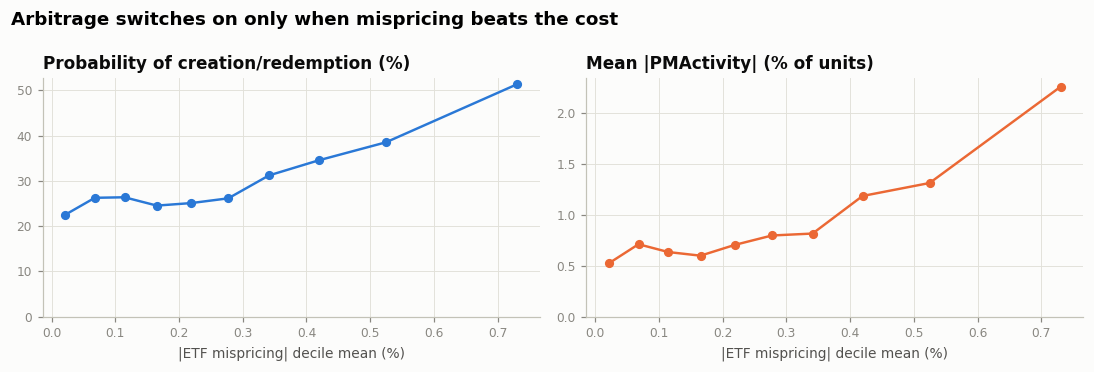

In [8]:
bins = etf.assign(bin=pd.qcut(etf["absMispricing"], 10, labels=False))
binned = bins.groupby("bin").agg(mis=("absMispricing", "mean"), p_pm=("PM_indicator", "mean"),
                                 size=("absPMActivity", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(binned["mis"], 100 * binned["p_pm"], color=C["blue"], marker="o", ms=5)
axes[0].set_title("Probability of creation/redemption (%)")
axes[0].set_xlabel("|ETF mispricing| decile mean (%)")
axes[0].set_ylim(0, None)
axes[1].plot(binned["mis"], binned["size"], color=C["orange"], marker="o", ms=5)
axes[1].set_title("Mean |PMActivity| (% of units)")
axes[1].set_xlabel("|ETF mispricing| decile mean (%)")
axes[1].set_ylim(0, None)
fig.suptitle("Arbitrage switches on only when mispricing beats the cost", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "sim_threshold")
plt.show()

### 2.3 Do HFTs arbitrage? (paper Table 4) — and does the test have power?

The paper regresses $HFTActivity$ on primary-market activity and $|mispricing|$ and finds nothing. A null result is only informative if the test **could** have found something. We therefore rerun the regression in a counterfactual market where HFT volume rises with $|mispricing|$ (`hft_arbitrage = 1`).

In [9]:
etf_hft_arb = simulate_etf_panel(market, hft_arbitrage=1.0)
t4 = {
    "Baseline: |PM|": fe_ols(etf, "HFTActivity", ["absMispricing", "absPMActivity"], "etf", "date"),
    "Baseline: 1_PM": fe_ols(etf, "HFTActivity", ["absMispricing", "PM_indicator"], "etf", "date"),
    "HFTs arbitrage: |PM|": fe_ols(etf_hft_arb, "HFTActivity", ["absMispricing", "absPMActivity"], "etf", "date"),
}
display(reg_table(t4, ["absMispricing", "absPMActivity", "PM_indicator"],
                  {"absMispricing": "|ETFMispricing|", "absPMActivity": "|PMActivity|", "PM_indicator": "1_PM"}))

,Baseline: |PM|,Baseline: 1_PM,HFTs arbitrage: |PM|
|ETFMispricing|,-0.174*,-0.198**,0.248**
|ETFMispricing|,(0.099),(0.097),(0.107)
|PMActivity|,-0.009,,0.049***
|PMActivity|,(0.012),,(0.014)
1_PM,,0.020,
1_PM,,(0.069),
Fixed effects,entity+time,entity+time,entity+time
Observations,"8,568","8,568","8,568"
R² (within),0.000,0.000,0.003


A single sample can produce a borderline coefficient by chance. The right question is about **size and power**: how often does the test reject at 5% when HFTs truly do not arbitrage, and how often when they do? We answer it with 30 simulated markets per scenario.

**Share of 30 simulations rejecting H0: coefficient = 0 at 5% (%)**

,|ETFMispricing|,|PMActivity|
HFTs don't arbitrage (size),7.000,10.000
HFTs arbitrage (power),100.000,100.000


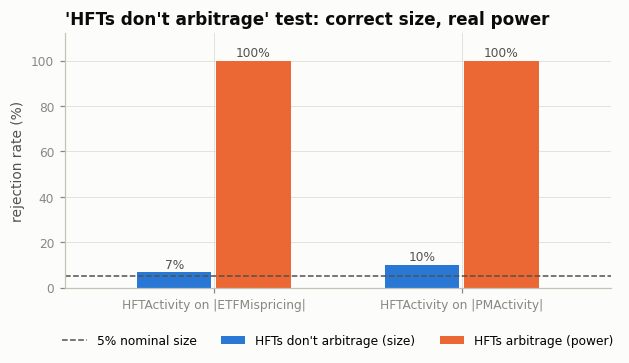

In [10]:
reps = 30
rej = {"HFTs don't arbitrage (size)": [], "HFTs arbitrage (power)": []}
for r in range(reps):
    m_r = simulate_market(seed=5_000 + r)
    for name, k in [("HFTs don't arbitrage (size)", 0.0), ("HFTs arbitrage (power)", 1.0)]:
        d = simulate_etf_panel(m_r, hft_arbitrage=k, seed=6_000 + r)
        tab, _ = fe_ols(d, "HFTActivity", ["absMispricing", "absPMActivity"], "etf", "date")
        rej[name].append((tab["t"].abs() > 1.96).to_numpy())
rejection = 100 * pd.DataFrame({k: np.mean(v, axis=0) for k, v in rej.items()},
                               index=["|ETFMispricing|", "|PMActivity|"]).T
display(Markdown(f"**Share of {reps} simulations rejecting H0: coefficient = 0 at 5% (%)**"))
display(rejection.round(0))

fig, ax = plt.subplots(figsize=(6.4, 3.0))
xpos = np.arange(2)
for j, (name, color) in enumerate([("HFTs don't arbitrage (size)", C["blue"]), ("HFTs arbitrage (power)", C["orange"])]):
    vals = rejection.loc[name].to_numpy()
    ax.bar(xpos + (j - 0.5) * 0.32, vals, width=0.3, color=color, label=name)
    for x, v in zip(xpos + (j - 0.5) * 0.32, vals):
        ax.text(x, v + 2, f"{v:.0f}%", ha="center", fontsize=8, color=C["ink2"])
ax.axhline(5, color=C["ink2"], lw=1, ls="--", label="5% nominal size")
ax.set_xticks(xpos, ["HFTActivity on |ETFMispricing|", "HFTActivity on |PMActivity|"])
ax.set_ylim(0, 112)
ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("rejection rate (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
ax.set_title("'HFTs don't arbitrage' test: correct size, real power")
savefig(fig, "sim_hft_power")
plt.show()

Under the null, rejections stay close to the nominal 5% (with 30 draws, simulation noise is about ±4 pp); when HFTs do trade the basis, the same specification detects it in most samples. So, at the paper's sample size, its null result for HFTs is informative at the daily frequency.

### 2.4 Comparative statics: how arbitrage costs shape the primary market

,PM days (%),s.d. true mispricing (%),s.d. measured mispricing (%),|PM| on PM days (%)
cost x,,,,
0.250,60.668,0.238,0.359,9.058
0.500,48.074,0.241,0.361,5.136
0.750,39.624,0.244,0.363,3.813
1.000,30.649,0.242,0.358,3.118
1.500,20.693,0.252,0.365,2.687
2.000,15.780,0.257,0.370,2.605
3.000,11.846,0.263,0.375,2.381


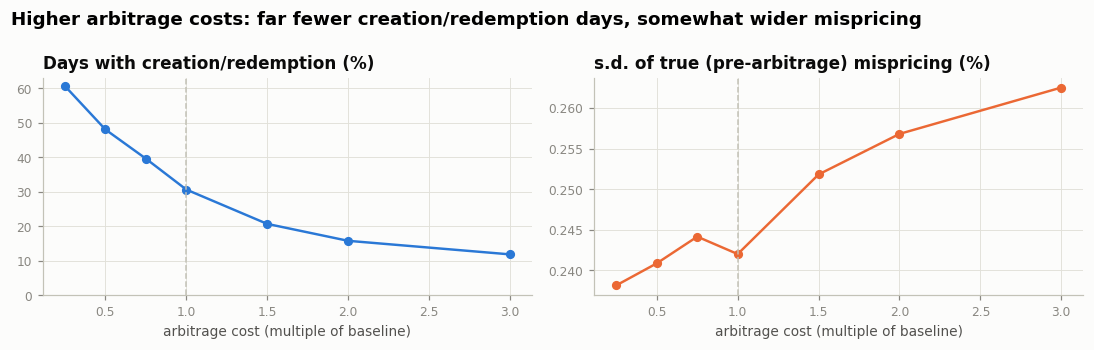

In [11]:
grid = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
cs = []
for k in grid:
    d = simulate_etf_panel(market, cost_scale=k)
    cs.append({"cost x": k, "PM days (%)": 100 * d["PM_indicator"].mean(),
               "s.d. true mispricing (%)": d["mis_true"].std(),
               "s.d. measured mispricing (%)": d["ETFMispricing"].std(),
               "|PM| on PM days (%)": d.loc[d["PM_indicator"] > 0, "absPMActivity"].mean()})
cs = pd.DataFrame(cs).set_index("cost x")
display(cs.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(cs.index, cs["PM days (%)"], color=C["blue"], marker="o", ms=5)
axes[0].set_title("Days with creation/redemption (%)")
axes[0].set_xlabel("arbitrage cost (multiple of baseline)")
axes[0].set_ylim(0, None)
axes[1].plot(cs.index, cs["s.d. true mispricing (%)"], color=C["orange"], marker="o", ms=5)
axes[1].set_title("s.d. of true (pre-arbitrage) mispricing (%)")
axes[1].set_xlabel("arbitrage cost (multiple of baseline)")
for ax in axes:
    ax.axvline(1.0, color=C["axis"], lw=1, ls="--")
fig.suptitle("Higher arbitrage costs: far fewer creation/redemption days, somewhat wider mispricing", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "sim_cost_statics")
plt.show()

## 3. Simulation lab II — constituent-stock market quality (paper §3, Table 5)

Take the large tracker `ETF00` and its 38 constituents.

**ETF ownership.** For a cap-weighted, physically replicating ETF, ownership of stock $i$ is $ETFOwn_i = MV_{ETF}\cdot ff_i/\sum_j ff_j MV_j$. It varies across stocks only through the free-float factor $ff_i$, which is exactly why the paper interacts it with the ETF-level activity measures.

**Data-generating process for the stocks**

- **Arbitrage channel.** Creating or redeeming $|PMActivity_t|$% of the ETF requires trading $ETFOwn_i\times|PMActivity_t|$% of stock $i$'s market value. This order imbalance raises volatility, spreads and inefficiency and lowers depth.
- **Information linkage.** Higher HFT activity in the ETF lowers spreads and inefficiency in proportion to $ETFOwn_i$.
- **Common shocks.** Market volatility moves all stocks together; the day fixed effects absorb it.

We then estimate the paper's equation (10) with stock and day fixed effects and double-clustered SEs.

In [12]:
def simulate_stock_panel(market, tracker, n_stocks=38, etf_mv=3800.0, seed=SEED + 2,
                         theta=dict(vol=1.2, spr=0.8, ineff=0.25, depth=-0.3),
                         eta=dict(spr=0.04, ineff=0.015)):
    rng = np.random.default_rng(seed)
    dates = market.index
    mv = np.sort(np.exp(rng.normal(np.log(25_000), 0.9, n_stocks)))[::-1]   # EUR m
    ff = rng.uniform(0.35, 1.0, n_stocks)
    own0 = 100 * etf_mv * ff / np.sum(ff * mv)                              # % of market value
    base_vol = rng.uniform(15, 35, n_stocks)
    base_spr = 4 * np.exp(-0.4 * np.log(mv / 25_000)) * rng.uniform(0.8, 1.2, n_stocks)
    turn = np.exp(rng.normal(np.log(0.004), 0.3, n_stocks))
    pm = tracker["absPMActivity"].to_numpy()
    hft = tracker["HFTActivity"].to_numpy()
    hft_dev = hft - hft.mean()
    vixf = np.log(market["vix"].to_numpy() / 24)
    rows = []
    for t in range(len(dates)):
        own = own0 * np.exp(0.02 * rng.standard_normal(n_stocks))
        x_pm, x_hft = own * pm[t], own * hft_dev[t]
        e = rng.standard_normal((5, n_stocks))
        rows.append(pd.DataFrame({
            "stock": [f"S{i:02d}" for i in range(n_stocks)], "date": dates[t], "ETFOwn": own,
            "absPMActivity": pm[t], "HFTActivity": hft[t],
            "Volatility": base_vol * (1 + theta["vol"] * x_pm + 0.20 * e[0]) + 20 * vixf[t],
            "QuotedSpread": base_spr * (1 + theta["spr"] * x_pm - eta["spr"] * x_hft + 0.12 * e[1]) + 1.5 * vixf[t],
            "Depth": np.log(mv / 100) - 0.6 * vixf[t] + theta["depth"] * x_pm + 0.25 * e[3],
            "Inefficiency": np.abs(0.10 + theta["ineff"] * x_pm - eta["ineff"] * x_hft + 0.07 * e[2]),
            "HFTStockActivity": np.log1p(mv * 1e6 / 50 * turn * 0.5 * np.exp(0.3 * e[4]))}))
    d = pd.concat(rows, ignore_index=True)
    d["ETFOwn_x_absPM"] = d["ETFOwn"] * d["absPMActivity"]
    d["ETFOwn_x_HFT"] = d["ETFOwn"] * d["HFTActivity"]
    return d

tracker = etf[etf["etf"] == "ETF00"].set_index("date").sort_index()
stocks = simulate_stock_panel(market, tracker)
outcomes = ["Volatility", "QuotedSpread", "Depth", "Inefficiency"]
t5 = {y: fe_ols(stocks, y, ["ETFOwn_x_absPM", "ETFOwn_x_HFT", "ETFOwn", "HFTStockActivity"], "stock", "date")
      for y in outcomes}
display(reg_table(t5, ["ETFOwn_x_absPM", "ETFOwn_x_HFT", "ETFOwn", "HFTStockActivity"],
                  {"ETFOwn_x_absPM": "ETFOwn × |PMActivity|", "ETFOwn_x_HFT": "ETFOwn × HFTActivity"}))

,Volatility,QuotedSpread,Depth,Inefficiency
ETFOwn × |PMActivity|,27.353***,3.809***,0.080,0.196***
ETFOwn × |PMActivity|,(5.644),(0.814),(0.099),(0.039)
ETFOwn × HFTActivity,-0.018,-0.154**,0.012,-0.020***
ETFOwn × HFTActivity,(0.353),(0.062),(0.017),(0.003)
ETFOwn,-2.751,2.767**,-1.005**,0.174
ETFOwn,(7.753),(1.374),(0.441),(0.120)
HFTStockActivity,0.124,0.003,0.009,0.002
HFTStockActivity,(0.158),(0.021),(0.008),(0.002)
Fixed effects,entity+time,entity+time,entity+time,entity+time
Observations,"9,576","9,576","9,576","9,576"


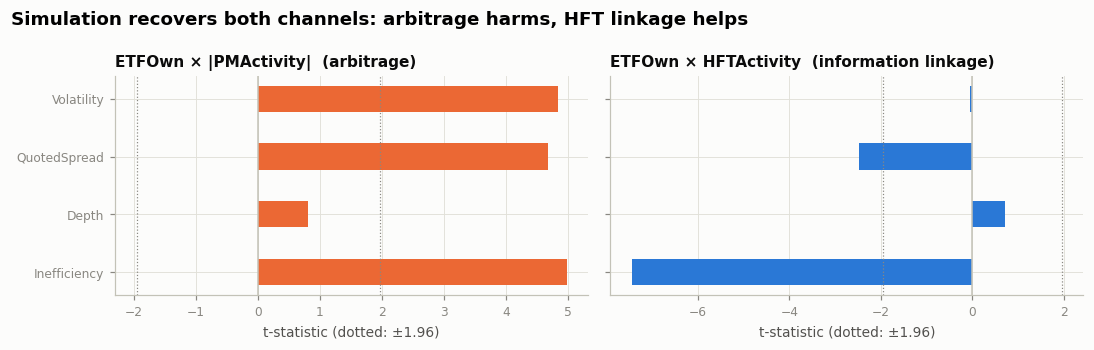

**Sign comparison with the paper's Table 5** (paper coefficients; simulation signs)

,Paper: ETFOwn×|PM|,Sim: sign ETFOwn×|PM|,Paper: ETFOwn×HFT,Sim: sign ETFOwn×HFT
Volatility,0.029,1.000,0.013,-1.000
QuotedSpread,0.004,1.000,-0.006,-1.000
Depth,0.017,1.000,0.004,1.000
Inefficiency,0.038,1.000,-0.027,-1.000


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (reg, title, color) in zip(axes, [("ETFOwn_x_absPM", "ETFOwn × |PMActivity|  (arbitrage)", C["orange"]),
                                          ("ETFOwn_x_HFT", "ETFOwn × HFTActivity  (information linkage)", C["blue"])]):
    t = np.array([t5[y][0].loc[reg, "t"] for y in outcomes])
    ypos = np.arange(len(outcomes))[::-1]
    ax.barh(ypos, t, height=0.45, color=color)
    ax.axvline(0, color=C["axis"], lw=1)
    for x in (-1.96, 1.96):
        ax.axvline(x, color=C["muted"], lw=0.8, ls=":")
    ax.set_yticks(ypos, outcomes)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("t-statistic (dotted: ±1.96)")
fig.suptitle("Simulation recovers both channels: arbitrage harms, HFT linkage helps", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "sim_table5_tstats")
plt.show()

comp = pd.DataFrame({
    "Paper: ETFOwn×|PM|": PAPER["table5"]["ETFOwn × |PMActivity|"],
    "Sim: sign ETFOwn×|PM|": [np.sign(t5[y][0].loc["ETFOwn_x_absPM", "coef"]) for y in outcomes],
    "Paper: ETFOwn×HFT": PAPER["table5"]["ETFOwn × HFTActivity"],
    "Sim: sign ETFOwn×HFT": [np.sign(t5[y][0].loc["ETFOwn_x_HFT", "coef"]) for y in outcomes],
})
display(Markdown("**Sign comparison with the paper's Table 5** (paper coefficients; simulation signs)"))
display(comp)

> **Reading the simulation honestly.** These regressions recover the channels because we **built** them into the data. The lab shows two things: the paper's specification can separate an arbitrage effect from an information-linkage effect when both exist, and the day fixed effects absorb market-wide shocks such as the volatility spike. It is **not** evidence that the channels exist in real markets; that is what the paper's data, and §5–6 here, are for.

## 4. The Bank of Japan experiment — design and Monte Carlo (paper §4)

**Why it identifies a causal effect.** From December 2010 the BoJ bought ETFs on days when the market fell in the morning, about ¥70bn per purchase day versus ≈¥25bn of normal daily trading in those ETFs. Each purchase forces APs to **create** units, i.e. to buy the underlying stocks. Two index designs coexist:

- **TOPIX** is cap-weighted, so the purchase of stock $i$ as a share of its market value is $\approx B^T_t/\text{TotalCap}_t$. That is the same for every stock and is absorbed by the day fixed effect.
- **Nikkei 225** is **price-weighted**: $w^N_i = P_i\,PAF_i/\sum_j P_j\,PAF_j$. The purchase share is therefore
$$\frac{B^N_t\, w^N_{i,t}}{P_{i,t}\,Shares_i} \;\propto\; \frac{PAF_i}{Shares_i}.$$
Stocks with **few shares relative to their index weight** (Fast Retailing, Fanuc, SoftBank, Tokyo Electron, …) receive BoJ-driven demand that is large relative to their size, and this is unrelated to their fundamentals.

The simulation below builds a "paper-sized" market: 225 Nikkei stocks, 175 non-Nikkei TOPIX stocks, 1,481 days, and BoJ purchases on the ≈24% of days with the weakest morning sessions. It then runs the paper's estimators, where the true effect is known.

In [14]:
def simulate_japan(n_nikkei=225, n_control=175, n_days=1481, seed=SEED + 3, nikkei_share=0.5,
                   truth=dict(Return=0.05, Volatility=0.6, QuotedSpread=0.002), rest_of_market_tn=350.0):
    rng = np.random.default_rng(seed)
    N = n_nikkei + n_control
    nikkei = np.r_[np.ones(n_nikkei, bool), np.zeros(n_control, bool)]
    shares = np.exp(rng.normal(np.log(300e6), 1.0, N))
    p0 = np.exp(rng.normal(np.log(2000), 0.9, N))
    paf = np.where(rng.random(N) < 0.85, 1.0, 0.1)
    ff = rng.uniform(0.4, 0.95, N)
    beta = 1 + 0.25 * rng.standard_normal(N)
    morning = rng.normal(0, 0.8, n_days)
    afternoon = rng.normal(0, 0.7, n_days)
    mkt = morning + afternoon
    boj = morning < np.quantile(morning, 349 / 1481)                    # 349 purchase days, as in the paper
    B = np.where(boj, 70e9 * rng.uniform(0.8, 1.2, n_days), 0.0)        # yen per purchase day
    logp = np.log(p0) + np.cumsum((beta * mkt[:, None] + rng.normal(0, 1.5, (n_days, N))) / 100 * 0.3, axis=0)
    P = np.exp(logp)
    MV = P * shares
    MV_lag = np.vstack([np.repeat(MV[:1], 22, 0), MV[:-22]])           # MarketValue_{t-22}
    P_prev = np.vstack([P[:1], P[:-1]])                                 # weights use the previous close
    wN = np.where(nikkei, P_prev * paf, 0.0)
    wN = wN / wN.sum(1, keepdims=True)
    wT = ff * MV / ((ff * MV).sum(1, keepdims=True) + rest_of_market_tn * 1e12)
    pms = 1e4 * B[:, None] * (nikkei_share * wN + (1 - nikkei_share) * wT) / MV_lag   # basis points of market value
    e = rng.standard_normal((3, n_days, N))
    out = {
        "Return": beta * mkt[:, None] + truth["Return"] * pms + 1.5 * e[0],
        "Volatility": rng.uniform(25, 45, N) + 6 * beta * np.abs(mkt)[:, None] + truth["Volatility"] * pms + 8 * e[1],
        "QuotedSpread": rng.uniform(0.1, 0.3, N) + truth["QuotedSpread"] * pms + 0.05 * e[2],
    }
    last = pd.DataFrame(np.where(boj[:, None], pms, np.nan)).ffill().fillna(0.0).to_numpy()
    idx = pd.MultiIndex.from_product([pd.bdate_range("2010-09-01", periods=n_days), [f"J{i:03d}" for i in range(N)]],
                                     names=["date", "stock"])
    df = pd.DataFrame({**{k: v.ravel() for k, v in out.items()}, "PMStockActivity": pms.ravel(),
                       "LastPMStockActivity": last.ravel(), "boj_day": np.repeat(boj, N),
                       "nikkei": np.tile(nikkei, n_days), "mkt_ret": np.repeat(mkt, N)}, index=idx)
    return df.reset_index()

TRUTH = dict(Return=0.05, Volatility=0.6, QuotedSpread=0.002)
jp = simulate_japan(truth=TRUTH)
on = jp[jp["boj_day"]]
print(f"{jp['stock'].nunique()} stocks x {jp['date'].nunique()} days; BoJ purchase days: {jp.loc[jp.boj_day, 'date'].nunique()}")
display(on.groupby("nikkei")["PMStockActivity"].describe().rename(index={True: "Nikkei 225", False: "TOPIX only"}).round(3))

400 stocks x 1481 days; BoJ purchase days: 349


,count,mean,std,min,25%,50%,75%,max
nikkei,,,,,,,,
TOPIX only,"61,075.000",0.303,0.084,0.132,0.234,0.297,0.365,0.550
Nikkei 225,"78,525.000",3.302,4.443,0.158,1.047,2.017,3.729,51.888


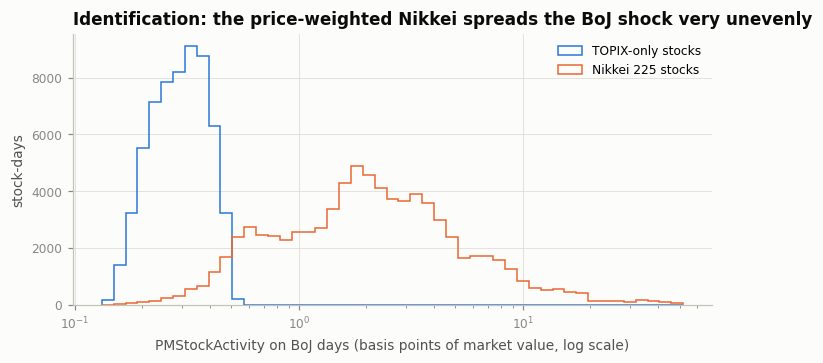

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
bins_ = np.logspace(np.log10(on["PMStockActivity"].min()), np.log10(on["PMStockActivity"].max()), 50)
ax.hist(on.loc[~on.nikkei, "PMStockActivity"], bins=bins_, histtype="step", lw=2, color=C["blue"], label="TOPIX-only stocks")
ax.hist(on.loc[on.nikkei, "PMStockActivity"], bins=bins_, histtype="step", lw=2, color=C["orange"], label="Nikkei 225 stocks")
ax.set_xscale("log")
ax.set_xlabel("PMStockActivity on BoJ days (basis points of market value, log scale)")
ax.set_ylabel("stock-days")
ax.legend(loc="upper right")
ax.set_title("Identification: the price-weighted Nikkei spreads the BoJ shock very unevenly")
savefig(fig, "jp_intensity")
plt.show()

### 4.1 Paper Table 8 on simulated data: Panels A, B and C

- **Panel A:** BoJ purchase days only; stock and day fixed effects; double-clustered SEs.
- **Panel B (counterfactual):** non-purchase days, with the placebo $LastPMStockActivity$ (the most recent non-zero value).
- **Panel C:** the Z-test of equation (13).

In [16]:
def table8(df, outcomes, x_on="PMStockActivity", x_off="LastPMStockActivity", entity="stock", time="date"):
    A = df[df["boj_day"]]
    Bd = df[~df["boj_day"]]
    rows = []
    for y in outcomes:
        ta, ia = fe_ols(A, y, [x_on], entity, time)
        tb, ib = fe_ols(Bd, y, [x_off], entity, time)
        z = z_test(ta.loc[x_on, "coef"], ta.loc[x_on, "se"], tb.loc[x_off, "coef"], tb.loc[x_off, "se"])
        rows.append({"outcome": y,
                     "A: coef": ta.loc[x_on, "coef"], "A: se": ta.loc[x_on, "se"], "A: t": ta.loc[x_on, "t"],
                     "B: coef": tb.loc[x_off, "coef"], "B: se": tb.loc[x_off, "se"], "B: t": tb.loc[x_off, "t"],
                     "C: Z": z, "N (A)": ia["N"], "N (B)": ib["N"]})
    return pd.DataFrame(rows).set_index("outcome")

t8_sim = table8(jp, list(TRUTH))
t8_sim.insert(0, "true effect", pd.Series(TRUTH))
display(t8_sim.round(4))

,true effect,A: coef,A: se,A: t,B: coef,B: se,B: t,C: Z,N (A),N (B)
outcome,,,,,,,,,,
Return,0.050,0.040,0.007,5.616,0.002,0.005,0.469,4.257,139600,452800
Volatility,0.600,0.637,0.031,20.534,0.024,0.022,1.096,16.105,139600,452800
QuotedSpread,0.002,0.002,0.000,6.658,-0.000,0.000,-0.362,5.907,139600,452800


### 4.2 Monte Carlo: is the estimator unbiased, and is the placebo clean?

We repeat the experiment 20 times with fresh randomness. If the design works, Panel A estimates centre on the true effect and Panel B estimates centre on zero.

In [ ]:
mc = []
for r in range(20):
    d = simulate_japan(seed=10_000 + r, truth=TRUTH)
    t = table8(d, list(TRUTH))
    for y in TRUTH:
        mc.append({"rep": r, "outcome": y, "A": t.loc[y, "A: coef"], "B": t.loc[y, "B: coef"], "Z": t.loc[y, "C: Z"]})
mc = pd.DataFrame(mc)
summary = mc.groupby("outcome").agg(A_mean=("A", "mean"), A_sd=("A", "std"), B_mean=("B", "mean"),
                                    B_sd=("B", "std"), Z_mean=("Z", "mean"))
summary.insert(0, "true", pd.Series(TRUTH))
display(summary.round(4))

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.0))
for ax, y in zip(axes, TRUTH):
    sub = mc[mc["outcome"] == y]
    ax.scatter(sub["A"] / TRUTH[y], np.full(len(sub), 1.0) + np.random.default_rng(0).uniform(-0.12, 0.12, len(sub)),
               s=22, color=C["orange"], label="Panel A: BoJ days")
    ax.scatter(sub["B"] / TRUTH[y], np.full(len(sub), 0.0) + np.random.default_rng(1).uniform(-0.12, 0.12, len(sub)),
               s=22, color=C["blue"], label="Panel B: placebo")
    ax.axvline(1, color=C["ink2"], lw=1, ls="--")
    ax.axvline(0, color=C["axis"], lw=1)
    ax.set_yticks([0, 1], ["placebo", "BoJ days"])
    ax.set_ylim(-0.6, 1.6)
    ax.set_xlabel("estimate / true effect")
    ax.set_title(y, fontsize=10)
axes[0].legend(loc="upper left", fontsize=7)
fig.suptitle("Monte Carlo (20 draws): estimates centre on the truth, placebo on zero", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
savefig(fig, "jp_montecarlo")
plt.show()

**What the design needs in real data.**

1. The BoJ's split between Nikkei and TOPIX ETFs must be known; in reality it changed in Oct 2016 and Apr 2021.
2. Purchase days are **selected** (weak mornings), so the day fixed effects are indispensable, and the placebo compares different market states.
3. Index weights and market value must be **predetermined**. The paper lags market value by 22 days. We also take Nikkei weights from the previous close: a price-weighted weight measured on day $t$ contains the day-$t$ price and correlates mechanically with day-$t$ returns. Our mock-data test of §5 produced a spurious t ≈ 5 on returns until we lagged it.
4. Effects on **redemptions** cannot be learned from this experiment; the BoJ only bought until 2024.

## 5. Real data I — the BoJ experiment on Japanese stocks

This section reruns §4 on **real Japanese stock data** and adds an extension the paper does not have, a **dose–response and placebo by policy regime**:

| Regime | BoJ rule | Expected effect of Nikkei intensity |
|---|---|---|
| Sep 2010 – Sep 2016 (paper's sample) | purchases split across TOPIX/Nikkei ETFs by AUM (≈ half Nikkei) | positive |
| Oct 2016 – Mar 2021 | ¥2.7trn of ¥5.7trn moved to TOPIX-only purchases | smaller |
| Apr 2021 – Mar 2024 | TOPIX ETFs only | **zero** (placebo with hypothetical Nikkei intensity) |

**Inputs you provide** in `data/` (the BoJ and Nikkei sites block simple scripted downloads, and their formats change):

1. `boj_etf_purchases.csv` with columns `date, amount_jpy_bn`: daily totals of the BoJ's regular ETF purchases. Source: BoJ → Statistics → Market Operations (daily results), or BoJ Time-Series Data Search.
2. `nikkei225_paf.csv` with columns `code, paf`: Nikkei 225 constituents (4-digit TSE codes) and their *current* price adjustment factors. Source: Nikkei Indexes → Nikkei 225 → constituents and weights. With split-adjusted prices, *current* PAF × adjusted price reproduces historical weights, because PAFs scale with splits.
3. *(optional)* `control_universe.csv` with column `code`: non-Nikkei TOPIX stocks used as controls.

Prices and volumes come from Yahoo Finance (`yfinance`). Daily-data substitutes for the paper's 5-minute measures:

- **Volatility:** Parkinson range estimator (annualised, %).
- **QuotedSpread:** Abdi–Ranaldo (2017) two-day estimator (%).
- **Illiquidity:** Amihud (2002) ratio, used in place of depth.
- **Return:** close-to-close (%).

In [18]:
def can_reach(host="query1.finance.yahoo.com", timeout=5):
    import socket
    try:
        socket.create_connection((host, 443), timeout=timeout).close()
        return True
    except OSError:
        return False

ONLINE = can_reach()
print("Yahoo Finance reachable:", ONLINE)

Yahoo Finance reachable: True


In [19]:
import time
import yfinance as yf

warnings.filterwarnings("ignore", category=DeprecationWarning, module="yfinance")   # pandas 3 deprecations inside yfinance

def download_ohlcv(tickers, start, end, batch=50, pause=2.0, retries=2):
    # Returns {field: DataFrame(date x ticker)} for Open/High/Low/Close/Adj Close/Volume.
    # Yahoo throttles large requests and silently returns empty columns, so download in batches of `batch`
    # tickers with a short pause, and retry the tickers that came back empty.
    tickers = list(tickers)
    fields = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    parts = {f: [] for f in fields}
    todo = tickers
    for attempt in range(retries + 1):
        for i in range(0, len(todo), batch):
            chunk = todo[i:i + batch]
            raw = yf.download(chunk, start=start, end=end, auto_adjust=False, progress=False, threads=True,
                              group_by="column")
            time.sleep(pause)
            if raw is None or raw.empty:
                continue
            if not isinstance(raw.columns, pd.MultiIndex):
                raw.columns = pd.MultiIndex.from_product([raw.columns, chunk[:1]])
            level = 0 if "Close" in raw.columns.get_level_values(0) else 1
            ok = raw.xs("Close", axis=1, level=level).notna().any()
            for f in fields:
                if f in raw.columns.get_level_values(level):
                    parts[f].append(raw.xs(f, axis=1, level=level).loc[:, ok[ok].index])
        have = set().union(*(p.columns for p in parts["Close"]))
        todo = [t for t in tickers if t not in have]
        if not todo:
            break
    if not parts["Close"]:
        raise RuntimeError("empty download")
    if todo:
        print(f"no Yahoo data for {len(todo)} of {len(tickers)} tickers:", ", ".join(todo))
    out = {f: pd.concat(p, axis=1).sort_index().reindex(columns=tickers) for f, p in parts.items() if p}
    # Yahoo pads Tokyo holidays and pre-listing periods with stale zero-volume rows (JAL shows Close = 1 before
    # its Sep 2012 relisting): treat untraded cells as missing and drop dates on which nothing traded
    traded = out["Volume"] > 0
    out = {f: x if f == "Volume" else x.where(traded) for f, x in out.items()}
    out = {f: x.loc[traded.any(axis=1)] for f, x in out.items()}
    # ... and drop isolated bad prints: a close more than 3x away from both neighbouring closes, e.g. 1321.T on
    # 6 Oct 2026, quoted at 1/100 of the surrounding prices after its 100:1 split
    lc = np.log(out["Close"])
    jump, back = lc - lc.ffill().shift(1), lc - lc.bfill().shift(-1)
    bad = (jump.abs() > np.log(3)) & (back.abs() > np.log(3)) & (np.sign(jump) == np.sign(back))
    out = {f: x.where(~bad) for f, x in out.items()}
    out["Open"] = out["Open"].where(out["Open"] > 0)
    return out


def split_lag(tk, shares):
    # Factor that puts Yahoo's current share count on the split basis of its split-adjusted prices. Prices are
    # adjusted for a split at once, but the share count can lag (Tokyo Electron's 5:1 split of 29 Sep 2026):
    # the count is stale if it still equals the pre-split level in Yahoo's share history
    try:
        info = tk.info
        split, factor = pd.Timestamp(info["lastSplitDate"], unit="s"), info["lastSplitFactor"]
        if not pd.Timestamp.now() - pd.Timedelta(days=365) < split <= pd.Timestamp.now():
            return 1.0
        a, b = (float(x) for x in factor.split(":"))
        pre = tk.get_shares_full(start=(split - pd.Timedelta(days=180)).date(), end=split.date()).min()
        stale = abs(shares / pre - 1) < 0.25 and abs(shares / (pre * a / b) - 1) >= 0.25
        return a / b if stale else 1.0
    except Exception:
        return 1.0


def shares_outstanding(tickers):
    # Current shares outstanding (split-consistent with Yahoo's split-adjusted prices)
    s = {}
    for t in tickers:
        tk = yf.Ticker(t)
        try:
            s[t] = float(tk.fast_info["shares"])
        except Exception:
            try:
                s[t] = float(tk.info.get("sharesOutstanding") or np.nan)
            except Exception:
                s[t] = np.nan
        s[t] *= split_lag(tk, s[t])
    return pd.Series(s)


def daily_quality(px):
    # Daily market-quality proxies from OHLCV (wide DataFrames date x ticker) -> long panel
    o, h, l, c, v = px["Open"], px["High"], px["Low"], px["Close"], px["Volume"]
    adj = px.get("Adj Close", c)
    ret = 100 * adj.pct_change(fill_method=None)
    park = 100 * np.sqrt(252 * np.log(h / l) ** 2 / (4 * np.log(2)))              # Parkinson (1980)
    eta = (np.log(h) + np.log(l)) / 2
    lc = np.log(c)
    ar2 = 4 * (lc - eta) * (lc - eta.shift(-1))                                   # Abdi & Ranaldo (2017)
    spread = 100 * np.sqrt(ar2.clip(lower=0))
    amihud = 1e12 * (ret.abs() / 100) / (c * v).where(c * v > 0)                 # |return| per trillion of turnover
    long = pd.concat({"Return": ret, "Volatility": park, "QuotedSpread": spread, "Illiquidity": amihud}, axis=1)
    long = long.stack(level=1, future_stack=True).rename_axis(["date", "ticker"]).reset_index()
    for col in ["Return", "Volatility", "QuotedSpread", "Illiquidity"]:
        long[col] = winsorize(long[col])
    return long

In [20]:
BOJ_FILE = DATA_DIR / "boj_etf_purchases.csv"
NIKKEI_FILE = DATA_DIR / "nikkei225_paf.csv"
CONTROL_FILE = DATA_DIR / "control_universe.csv"
START, END = "2010-08-01", "2024-03-31"
REGIMES = [("2010-09-01", "2016-09-30", "Sep 2010 – Sep 2016 (paper)"),
           ("2016-10-01", "2021-03-31", "Oct 2016 – Mar 2021"),
           ("2021-04-01", "2024-03-19", "Apr 2021 – Mar 2024 (placebo)")]
# Approximate Nikkei share of regular purchases by regime: AUM-proportional (~0.5) before Oct 2016;
# 3.0/5.7 of purchases AUM-proportional afterwards (~0.25); TOPIX only from Apr 2021. Adjust if you have better data.
NIKKEI_SHARE = {REGIMES[0][2]: 0.50, REGIMES[1][2]: 0.25, REGIMES[2][2]: 0.0}


def regime_of(date):
    for a, b, name in REGIMES:
        if pd.Timestamp(a) <= date <= pd.Timestamp(b):
            return name
    return None


def build_boj_panel(boj, paf, controls, px, shares):
    # Panel with PMStockActivity (bps of market value) from the Nikkei leg; the TOPIX leg is common to all stocks
    nk = [f"{c}.T" for c in paf.index]
    close = px["Close"]
    mv_lag = (close * shares.reindex(close.columns)).shift(22)
    # Weights known before the purchase day: with a price-weighted index, day-t weights contain the day-t price
    # and would correlate mechanically with day-t returns
    w = (close[nk] * paf.set_axis(nk)).shift(1)
    w = w.div(w.sum(axis=1), axis=0)
    amount = boj.reindex(close.index).fillna(0.0) * 1e9                              # yen
    intensity = 1e4 * 0.5 * w.mul(amount, axis=0) / mv_lag[nk]                      # hypothetical 50% Nikkei share
    intensity = intensity.reindex(columns=close.columns).fillna(0.0)
    q = daily_quality(px)
    q = q.merge(intensity.stack().rename("Intensity").rename_axis(["date", "ticker"]).reset_index(), on=["date", "ticker"])
    q["boj_day"] = q["date"].map(lambda d: amount.get(d, 0) > 0)
    q["regime"] = q["date"].map(regime_of)
    q["nikkei"] = q["ticker"].isin(nk)
    q["PMStockActivity"] = q["Intensity"] * q["regime"].map(NIKKEI_SHARE).fillna(0) / 0.5
    q = q.dropna(subset=["regime"]).sort_values(["ticker", "date"])
    last = q["PMStockActivity"].where(q["boj_day"])
    q["LastPMStockActivity"] = last.groupby(q["ticker"]).ffill().fillna(0.0)
    last_i = q["Intensity"].where(q["boj_day"])
    q["LastIntensity"] = last_i.groupby(q["ticker"]).ffill().fillna(0.0)
    return q


have_inputs = BOJ_FILE.exists() and NIKKEI_FILE.exists()
if not (ONLINE and have_inputs):
    print("Skipping §5:", "no internet;" if not ONLINE else "", "missing data/ inputs." if not have_inputs else "")
    print("Provide", BOJ_FILE, "and", NIKKEI_FILE, "(see the instructions above) and re-run this section.")
    boj_panel = None
else:
    boj = pd.read_csv(BOJ_FILE, parse_dates=["date"]).groupby("date")["amount_jpy_bn"].sum()
    paf = pd.read_csv(NIKKEI_FILE, dtype={"code": str}).set_index("code")["paf"].astype(float)
    controls = (pd.read_csv(CONTROL_FILE, dtype={"code": str})["code"].tolist() if CONTROL_FILE.exists() else [])
    tickers = sorted({f"{c}.T" for c in list(paf.index) + controls})
    print(f"downloading {len(tickers)} tickers from Yahoo Finance ...")
    px = download_ohlcv(tickers, START, END)
    shares = shares_outstanding(tickers)
    boj_panel = build_boj_panel(boj, paf, controls, px, shares)
    print(boj_panel.groupby("regime")["boj_day"].agg(["size", "sum"]).rename(columns={"size": "stock-days", "sum": "BoJ stock-days"}))

downloading 493 tickers from Yahoo Finance ...


$285A.T: Data doesn't exist for startDate = 1280588400, endDate = 1711810800



1 Failed download:


['285A.T']: Data doesn't exist for startDate = 1280588400, endDate = 1711810800


$5016.T: Data doesn't exist for startDate = 1280588400, endDate = 1711810800


...

$5016.T: Data doesn't exist for startDate = 1280588400, endDate = 1711810800



6 Failed downloads:


['7240.T', '8729.T', '285A.T', '9023.T', '9508.T', '5016.T']: Data doesn't exist for startDate = 1280588400, endDate = 1711810800


no Yahoo data for 6 of 493 tickers: 285A.T, 5016.T, 7240.T, 8729.T, 9023.T, 9508.T


                               stock-days  BoJ stock-days
regime                                                   
Apr 2021 – Mar 2024 (placebo)      357918            7888
Oct 2016 – Mar 2021                540328          159239
Sep 2010 – Sep 2016 (paper)        734570          175015


In [21]:
if boj_panel is not None:
    outcomes_real = ["Return", "Volatility", "QuotedSpread", "Illiquidity"]
    paper_period = boj_panel[boj_panel["regime"] == REGIMES[0][2]]
    display(Markdown("**Table 8 replication on real data, Sep 2010 – Sep 2016** (A: BoJ days; B: placebo; C: Z-test)"))
    display(table8(paper_period, outcomes_real, entity="ticker").round(4))

    display(Markdown("**Extension: dose–response by BoJ regime** (BoJ days; slope on Nikkei-leg intensity)"))
    ext = []
    for _, _, name in REGIMES:
        sub = boj_panel[(boj_panel["regime"] == name) & boj_panel["boj_day"]]
        x = "PMStockActivity" if NIKKEI_SHARE[name] > 0 else "Intensity"   # last regime: hypothetical intensity
        for y in outcomes_real:
            tab, info = fe_ols(sub, y, [x], "ticker", "date")
            ext.append({"regime": name, "outcome": y, "regressor": x, "coef": tab.loc[x, "coef"],
                        "se": tab.loc[x, "se"], "t": tab.loc[x, "t"], "N": info["N"]})
    display(pd.DataFrame(ext).set_index(["regime", "outcome"]).round(4))

**Table 8 replication on real data, Sep 2010 – Sep 2016** (A: BoJ days; B: placebo; C: Z-test)

,A: coef,A: se,A: t,B: coef,B: se,B: t,C: Z,N (A),N (B)
outcome,,,,,,,,,
Return,-0.027,0.034,-0.786,-0.033,0.018,-1.860,0.163,161598,508875
Volatility,-0.031,0.221,-0.140,0.243,0.180,1.349,-0.960,161926,511012
QuotedSpread,-0.010,0.019,-0.538,0.008,0.010,0.783,-0.833,161456,510407
Illiquidity,-3.693,1.799,-2.053,-3.075,1.347,-2.282,-0.275,161598,508875


**Extension: dose–response by BoJ regime** (BoJ days; slope on Nikkei-leg intensity)

regressor   coef    se  \
regime                        outcome                                      
Sep 2010 – Sep 2016 (paper)   Return        PMStockActivity -0.027 0.034   
                              Volatility    PMStockActivity -0.031 0.221   
                              QuotedSpread  PMStockActivity -0.010 0.019   
                              Illiquidity   PMStockActivity -3.693 1.799   
Oct 2016 – Mar 2021           Return        PMStockActivity -0.153 0.118   
                              Volatility    PMStockActivity -0.854 0.457   
                              QuotedSpread  PMStockActivity  0.050 0.073   
                              Illiquidity   PMStockActivity -2.023 0.677   
Apr 2021 – Mar 2024 (placebo) Return              Intensity  1.004 0.612   
                              Volatility          Intensity -1.048 2.543   
                              QuotedSpread        Intensity  0.116 0.191   
                              Illiquidity         Intensity -3.704 1.610   

                                                t       N  
regime                        outcome                      
Sep 2010 – Sep 2016 (paper)   Return       -0.786  161598  
                              Volatility   -0.140  161926  
                              QuotedSpread -0.538  161456  
                              Illiquidity  -2.053  161598  
Oct 2016 – Mar 2021           Return       -1.288  153197  
                              Volatility   -1.867  153200  
                              QuotedSpread  0.689  153197  
                              Illiquidity  -2.988  153197  
Apr 2021 – Mar 2024 (placebo) Return        1.641    7703  
                              Volatility   -0.412    7704  
                              QuotedSpread  0.610    7704  
                              Illiquidity  -2.300    7703

## 6. Real data II — open-market checks with Yahoo Finance

### 6.1 Is the ETF more liquid than its basket? (paper Table 6)

The paper finds that the Lyxor CAC 40 ETF's quoted spread (2.6 bps) is well below the weighted spread of its constituents (4.7 bps). It also finds that the ETF's spread co-moves with the constituents' spreads (information linkage). We check the same two facts for:

- **SPY** against its largest holdings;
- **Nomura Nikkei 225 ETF (1321.T)** against Nikkei heavyweights.

Spreads come from the **EDGE** estimator (Ardia, Guidotti & Kroencke, 2024), computed month by month from daily OHLC prices. The basket spread is cap-weighted using current market capitalisation, or equal-weighted if that is unavailable.

In [22]:
from bidask import edge

PAIRS = {
    "SPY": ["NVDA", "MSFT", "AAPL", "AMZN", "META", "AVGO", "GOOGL", "TSLA", "BRK-B", "JPM"],
    "1321.T": ["9983.T", "8035.T", "9984.T", "6857.T", "6954.T", "9433.T", "6367.T", "4543.T", "6971.T", "4063.T"],
}
ETF_START, ETF_END = "2021-01-01", None


def monthly_edge(px, ticker):
    df = pd.DataFrame({k: px[k][ticker] for k in ["Open", "High", "Low", "Close"]}).dropna()
    return df.groupby(df.index.to_period("M")).apply(
        lambda g: edge(g["Open"], g["High"], g["Low"], g["Close"]) if len(g) >= 10 else np.nan) * 1e4   # bps


def caps(tickers):
    out = {}
    for t in tickers:
        try:
            tk = yf.Ticker(t)
            out[t] = float(tk.fast_info["market_cap"]) * split_lag(tk, float(tk.fast_info["shares"]))
        except Exception:
            out[t] = np.nan
    s = pd.Series(out)
    return s / s.sum() if s.notna().all() and s.sum() > 0 else pd.Series(1 / len(tickers), index=tickers)


etf_vs_basket = {}
if ONLINE:
    for etf_t, basket in PAIRS.items():
        px = download_ohlcv([etf_t, *basket], ETF_START, ETF_END)
        sp = pd.DataFrame({t: monthly_edge(px, t) for t in [etf_t, *basket]})
        w = caps(basket)
        out = pd.DataFrame({"ETF spread": sp[etf_t], "Basket spread": (sp[basket] * w).sum(axis=1, min_count=5)})
        out["Difference"] = out["Basket spread"] - out["ETF spread"]
        etf_vs_basket[etf_t] = out.dropna()
    display(pd.concat({k: v.describe().T[["count", "mean", "std", "25%", "50%", "75%"]]
                       for k, v in etf_vs_basket.items()}).round(2))
else:
    print("Skipping §6.1: Yahoo Finance not reachable.")

count   mean    std    25%    50%    75%
SPY    ETF spread    70.000 32.840 22.310 16.730 30.470 41.790
       Basket spread 70.000 71.370 28.910 52.400 66.570 81.110
       Difference    70.000 38.530 20.180 24.380 36.910 52.450
1321.T ETF spread    70.000 42.550 26.430 28.200 35.620 50.820
       Basket spread 70.000 84.290 32.220 65.360 77.880 91.590
       Difference    70.000 41.750 25.640 24.910 37.360 50.510

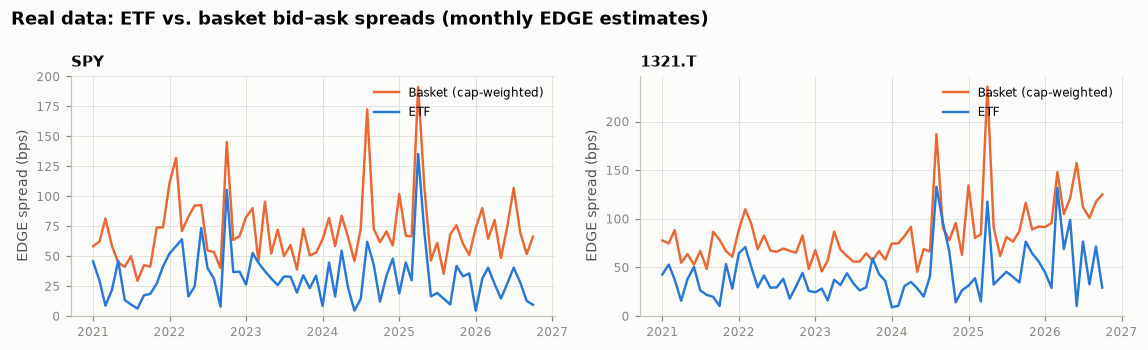

**Basket spread on ETF spread** (paper Table 6 Panel C analogue; Newey–West SEs)

,beta(ETF spread),t,beta(lag),t(lag),R2,months
pair,,,,,,
SPY,0.951,7.797,-0.086,-0.985,0.530,69
1321.T,0.758,3.984,0.085,0.476,0.406,69


In [23]:
if etf_vs_basket:
    fig, axes = plt.subplots(1, len(etf_vs_basket), figsize=(10.5, 3.2))
    for ax, (name, d) in zip(np.atleast_1d(axes), etf_vs_basket.items()):
        x = d.index.to_timestamp()
        ax.plot(x, d["Basket spread"], color=C["orange"], label="Basket (cap-weighted)")
        ax.plot(x, d["ETF spread"], color=C["blue"], label="ETF")
        ax.set_title(name, fontsize=10)
        ax.set_ylabel("EDGE spread (bps)")
        ax.set_ylim(0, None)
        ax.legend(loc="upper right")
    fig.suptitle("Real data: ETF vs. basket bid–ask spreads (monthly EDGE estimates)", x=0.01, ha="left",
                 fontsize=12, fontweight="bold")
    fig.tight_layout()
    savefig(fig, "real_etf_vs_basket")
    plt.show()

    rows = []
    for name, d in etf_vs_basket.items():
        X = sm.add_constant(pd.DataFrame({"ETF spread": d["ETF spread"], "ETF spread (t-1)": d["ETF spread"].shift(1)}))
        res = sm.OLS(d["Basket spread"], X, missing="drop").fit(cov_type="HAC", cov_kwds={"maxlags": 3})
        rows.append({"pair": name, "beta(ETF spread)": res.params["ETF spread"], "t": res.tvalues["ETF spread"],
                     "beta(lag)": res.params["ETF spread (t-1)"], "t(lag)": res.tvalues["ETF spread (t-1)"],
                     "R2": res.rsquared, "months": int(res.nobs)})
    display(Markdown("**Basket spread on ETF spread** (paper Table 6 Panel C analogue; Newey–West SEs)"))
    display(pd.DataFrame(rows).set_index("pair").round(3))

### 6.2 Did Japanese market quality improve while ETF ownership surged? (paper Table 9) — with a tick-size control

The paper regresses market quality on a time trend over 2010–2016 and reads the improvement as evidence that ETF benefits dominate. But the Tokyo Stock Exchange **cut tick sizes** for TOPIX100 stocks on 14 Jan 2014 and 22 Jul 2014, and reset them on 24 Sep 2015. Smaller ticks narrow quoted spreads mechanically. We therefore re-estimate the trend for large TOPIX100/Nikkei names:

- with **Newey–West** standard errors, because monthly averages are autocorrelated;
- with and without **tick-regime dummies**.

slope per year  t (Newey-West)    R2
outcome            model                                                     
QuotedSpread (bps) trend only                     1.057           0.699 0.008
                   trend + tick regimes           2.645           0.838 0.093
Volatility (%)     trend only                     0.554           1.294 0.036
                   trend + tick regimes           1.622           1.575 0.219

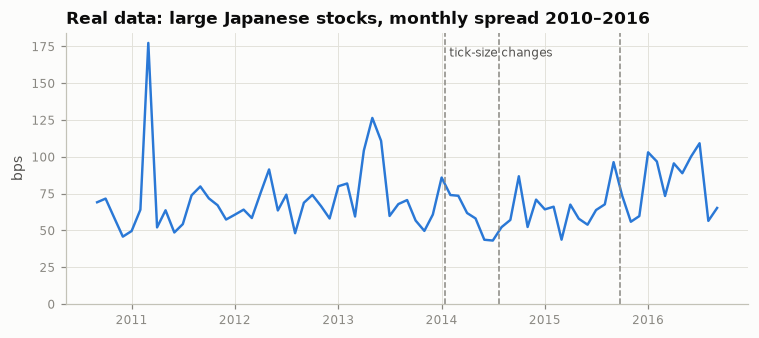

In [24]:
JP_LARGE = ["7203.T", "6758.T", "9983.T", "9984.T", "6954.T", "8035.T", "9433.T", "6367.T", "4063.T", "6971.T",
            "4543.T", "4502.T", "4503.T", "8306.T", "8058.T", "6301.T", "7267.T", "6501.T", "7974.T", "4519.T",
            "6762.T", "6857.T", "4911.T", "6988.T", "8031.T"]
TICK_DATES = ["2014-01-14", "2014-07-22", "2015-09-24"]

trend = None
if ONLINE:
    pxj = download_ohlcv(JP_LARGE, "2010-09-01", "2016-09-30")
    spreads = pd.DataFrame({t: monthly_edge(pxj, t) for t in JP_LARGE})
    park = 100 * np.sqrt(252 * np.log(pxj["High"] / pxj["Low"]) ** 2 / (4 * np.log(2)))
    vol_m = park.groupby(park.index.to_period("M")).mean()
    w = caps(JP_LARGE)
    trend = pd.DataFrame({"QuotedSpread (bps)": (spreads * w).sum(axis=1, min_count=10),
                          "Volatility (%)": (vol_m * w).sum(axis=1, min_count=10)}).dropna()
    ts = trend.index.to_timestamp()
    trend["time (years)"] = (ts - ts[0]).days / 365.25
    for i, d0 in enumerate(TICK_DATES, 1):
        trend[f"tick regime {i}"] = (ts >= pd.Timestamp(d0)).astype(float)

    rows = []
    for y in ["QuotedSpread (bps)", "Volatility (%)"]:
        for label, cols in [("trend only", ["time (years)"]),
                            ("trend + tick regimes", ["time (years)"] + [f"tick regime {i}" for i in (1, 2, 3)])]:
            res = sm.OLS(trend[y], sm.add_constant(trend[cols])).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
            rows.append({"outcome": y, "model": label, "slope per year": res.params["time (years)"],
                         "t (Newey-West)": res.tvalues["time (years)"], "R2": res.rsquared})
    display(pd.DataFrame(rows).set_index(["outcome", "model"]).round(3))

    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.plot(ts, trend["QuotedSpread (bps)"], color=C["blue"], label="cap-weighted EDGE spread")
    for d0 in TICK_DATES:
        ax.axvline(pd.Timestamp(d0), color=C["muted"], lw=1, ls="--")
    ax.text(pd.Timestamp(TICK_DATES[0]), ax.get_ylim()[1] * 0.95, " tick-size changes", fontsize=8, color=C["ink2"], va="top")
    ax.set_ylabel("bps")
    ax.set_ylim(0, None)
    ax.set_title("Real data: large Japanese stocks, monthly spread 2010–2016")
    savefig(fig, "real_jp_trend")
    plt.show()
else:
    print("Skipping §6.2: Yahoo Finance not reachable.")

## 7. Takeaways and limitations

**What the paper shows**

1. The ETF primary market is small and infrequent: 32% of days and 13% of secondary volume. It is driven by mispricing beyond a cost threshold.
2. HFTs dominate secondary trading (≈74%) and do not arbitrage.
3. Arbitrage goes with worse market quality in overweighted stocks; HFT activity goes with narrower spreads.
4. BoJ-induced creations **cause** higher volatility and illiquidity in overweighted Japanese stocks, but the long-run trend suggests that the benefits dominate.

**What this notebook adds**

- A transparent **simulation** of the AP/HFT ecosystem that reproduces Tables 2–5 qualitatively. It also shows that the "HFTs don't arbitrage" test has power, and how arbitrage costs shape primary-market frequency.
- A **Monte Carlo** check of the BoJ design: unbiased Panel A, clean placebo.
- **Open-data modules** for the BoJ experiment, extended to a regime-based dose–response and placebo, and for the liquidity spill-over and trend analyses. The trend analysis adds Newey–West SEs and tick-size controls.

**Limitations of our approach**

- Simulated results illustrate mechanisms by construction; they are not evidence.
- Daily OHLC proxies are noisier than the paper's 5-minute measures, and resiliency cannot be computed.
- Current index membership and current share counts introduce survivorship and measurement error.
- The BoJ input files must be supplied manually.

**Critical points on the paper** (detailed in `research_notes.md`)

- The French evidence is one year and one ETF for the stock-level tests.
- The BoJ experiment speaks only to creations, under extreme purchase sizes.
- The time-trend evidence for "benefits dominate" is confounded by the 2014–2015 tick-size reform.
- The BoJ began **selling** ETFs in January 2026, at ≈¥330bn a year at book value. That offers a new, if very slow, redemption-side experiment.